# ECHO — Autoregressive Text Generation with Simple RNN, Bidirectional RNN, LSTM and GRU

**Foundations of Generative AI (ICT4403) · Assignment 2** · Ryan Gupta (230953288)

**Problem.** Build a word-level autoregressive text generator — a model that predicts the next word from the words
before it and writes text by feeding its own predictions back in — and compare four recurrent architectures trained
under identical conditions.

**Objectives**
1. Describe and preprocess a text dataset; build input–target sequences for next-word prediction. *(Task i)*
2. Train Simple RNN, Bidirectional RNN, LSTM and GRU under comparable conditions. *(Task i)*
3. Compare them on loss, perplexity, accuracy and training time, and on the coherence, diversity, contextual
   consistency and repetition of their generated text. *(Task ii)*
4. Generate from the same seeds at several sampling temperatures, analyse the effect, and justify the best model. *(Task iii)*

> This notebook is the narrative front-end. The heavy lifting lives in `src/echo/` and `scripts/`; every cell below
> calls that code, so the numbers here are the numbers in the README.

In [1]:
import sys, json, math
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import yaml, torch, pandas as pd
from IPython.display import Image, Markdown, display
from echo.data import Vocab, tokenize, detokenize, EOS
from echo.models import build, count_params, KINDS, DISPLAY
from echo.generate import load_model, generate
from echo.train import device

pd.set_option("display.precision", 3)
cfg = yaml.safe_load((ROOT / "configs" / "default.yaml").read_text())
M = ROOT / "results" / "metrics"; P = ROOT / "results" / "plots"
print("device:", device(), "| torch", torch.__version__)
cfg

device: mps | torch 2.14.1


{'data': {'dataset': 'roneneldan/TinyStories',
  'train_stories': 30000,
  'val_stories': 2500,
  'test_stories': 2500,
  'vocab_size': 8000,
  'window': 24},
 'model': {'embed_dim': 128,
  'hidden_dim': 256,
  'num_layers': 2,
  'dropout': 0.25,
  'transformer': {'d_model': 192,
   'layers': 4,
   'heads': 6,
   'ff': 768,
   'dropout': 0.1}},
 'train': {'batch_size': 512,
  'lr': 0.002,
  'weight_decay': 0.01,
  'grad_clip': 1.0,
  'samples_per_epoch': 2000000,
  'max_epochs': 8,
  'patience': 2,
  'seeds': [13, 42, 2026]},
 'generate': {'temperatures': [0.0, 0.5, 0.8, 1.0, 1.3],
  'samples_per_setting': 5,
  'length': 60,
  'seeds_text': ['once upon a time , there was a little girl named lily . she',
   'one day , a big dog found a red ball in the park . the dog',
   'tom wanted to help his mom bake a cake . he',
   'the sun was hot , so the children went to the',
   'sam was sad because he lost his favorite toy . his friend']}}

## 1 · Dataset — TinyStories *(Task i)*

**Source:** [roneneldan/TinyStories on Hugging Face](https://huggingface.co/datasets/roneneldan/TinyStories) ·
paper: [Eldan & Li, 2023](https://arxiv.org/abs/2305.07759).

TinyStories is a synthetic corpus of short stories written (by GPT-3.5/4) using only words a typical 3–4-year-old
understands. It was designed precisely so that *small* language models can learn grammar, consistency and simple
reasoning — which makes it an ideal benchmark for compact recurrent networks.

We use the first 30,000 stories of the official **train** split for training, and two disjoint slices of 2,500
stories each from the official **validation** split for validation and test.

In [2]:
stats = json.loads((M / "dataset_stats.json").read_text())
pd.DataFrame({
    "stories": stats["stories"], "tokens": stats["tokens"],
    "(window → next) pairs": stats["examples"], "<unk> rate": stats["unk_rate"],
}).T

,train,val,test
stories,3.000e+04,2500.000,2500.000
tokens,6.213e+06,473797.000,458813.000
(window → next) pairs,6.213e+06,473773.000,458789.000
<unk> rate,1.301e-03,0.003,0.003


unique words in train: 12,951
vocabulary: 8,000 (covers 99.87% of training tokens)
words per story: {'mean': 206.1, 'min': 53, 'max': 1024}


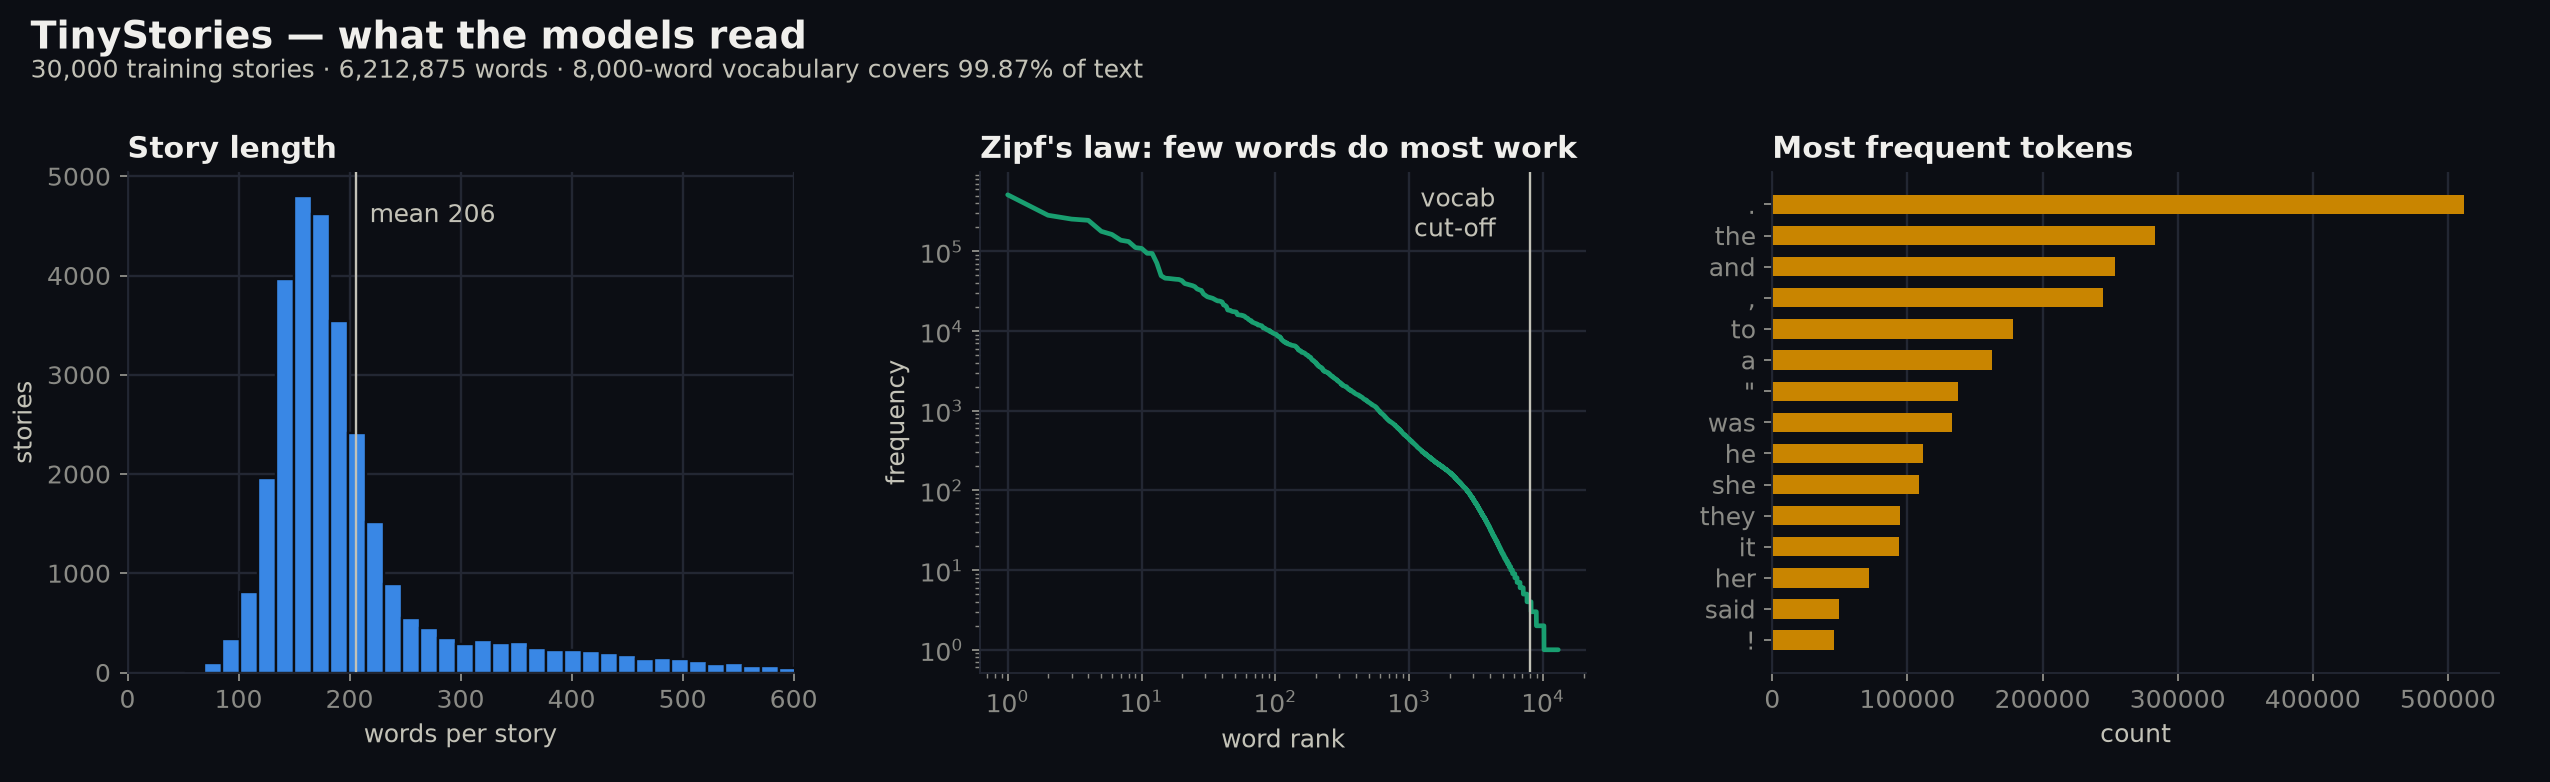

In [3]:
print(f"unique words in train: {stats['unique_words_train']:,}")
print(f"vocabulary: {stats['vocab_size']:,} (covers {stats['train_coverage']:.2%} of training tokens)")
print("words per story:", {k: round(v, 1) for k, v in stats['words_per_story'].items()})
display(Image(P / "01_dataset.png"))

### Preprocessing
1. **Normalise** unicode quotes/dashes and lowercase everything.
2. **Tokenise** into words (keeping contractions such as *don't*) and the punctuation marks `. , ! ? ; : "`,
   so the models learn sentence structure and dialogue.
3. **Join** stories into one stream separated by an `<eos>` token, so models also learn where stories end.
4. **Vocabulary** = 8,000 most frequent training tokens + `<pad>`, `<unk>`, `<eos>`; rarer words map to `<unk>`.

In [4]:
raw = json.loads((ROOT / "data" / "raw" / "stories.json").read_text())["train"][3]
print(raw[:300], "...\n")
toks = tokenize(raw)
print(toks[:40])
vocab = Vocab.load(ROOT / "data" / "processed" / "vocab.json")
print("ids:", vocab.encode(toks[:12]))

Once upon a time, in a land full of trees, there was a little cherry tree. The cherry tree was very sad because it did not have any friends. All the other trees were big and strong, but the cherry tree was small and weak. The cherry tree was envious of the big trees.

One day, the cherry tree felt a ...

['once', 'upon', 'a', 'time', ',', 'in', 'a', 'land', 'full', 'of', 'trees', ',', 'there', 'was', 'a', 'little', 'cherry', 'tree', '.', 'the', 'cherry', 'tree', 'was', 'very', 'sad', 'because', 'it', 'did', 'not', 'have', 'any', 'friends', '.', 'all', 'the', 'other', 'trees', 'were', 'big', 'and']
ids: [45, 47, 8, 37, 6, 18, 8, 1073, 443, 26, 441, 6]


### Input–target sequences for autoregressive modelling
With a context window of **W = 24 tokens**, every position *t* of the token stream gives one training pair:

$$x_t = (w_t,\dots,w_{t+W-1}) \quad\longrightarrow\quad y_t = w_{t+W}$$

This *many-to-one* framing is used for **all four** models. It matters for the Bidirectional RNN: because the
target lies strictly *after* the window, reading the window backwards never reveals the answer (no future leakage).
A per-timestep "shifted sequence" framing would leak the target to the backward RNN.

Windows are gathered on the GPU from the token stream on the fly (6.2M pairs never need to be materialised).

In [5]:
from echo.data import WindowBatcher
ids = torch.load(ROOT / "data" / "processed" / "train.pt")
b = WindowBatcher(ids[:5000], cfg["data"]["window"], 3, "cpu", shuffle=False)
x, y = next(iter(b))
for xi, yi in zip(x, y):
    print(" ".join(vocab.decode(xi)), " ──▶ ", vocab.itos[yi])

one day , a little girl named lily found a needle in her room . she knew it was difficult to play with it  ──▶  because
day , a little girl named lily found a needle in her room . she knew it was difficult to play with it because  ──▶  it
, a little girl named lily found a needle in her room . she knew it was difficult to play with it because it  ──▶  was


## 2 · Models *(Task i)*

All four share one skeleton — only the recurrent cell changes:

`word ids → Embedding(128) → 2-layer recurrent core (hidden 256, dropout 0.25) → last state → Linear → 8,000-way softmax`

| Model | Cell | Context vector |
|---|---|---|
| Simple RNN | $h_t=\tanh(W_x x_t + W_h h_{t-1} + b)$ | final hidden state |
| Bidirectional RNN | two tanh RNNs, left→right and right→left over the window | $[\overrightarrow{h}_W ; \overleftarrow{h}_1]$ |
| LSTM | input/forget/output gates + cell state $c_t$ | final hidden state |
| GRU | update/reset gates, no separate cell | final hidden state |

In [6]:
rows = []
for k in KINDS:
    m = build(k, len(vocab), cfg["model"])
    rows.append({"model": DISPLAY[k], **count_params(m)})
print(build("lstm", len(vocab), cfg["model"]))
pd.DataFrame(rows).set_index("model")

RecurrentLM(
  (embed): Embedding(8000, 128)
  (core): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.25)
  (drop): Dropout(p=0.25, inplace=False)
  (head): Linear(in_features=256, out_features=8000, bias=True)
)


,total,recurrent_core
model,,
Simple RNN,3310400,230400
Bidirectional RNN,5719872,591872
LSTM,4001600,921600
GRU,3771200,691200


In [7]:
# Why many-to-one matters for the BiRNN — an empirical leakage test.
# In a per-timestep ("shifted sequence") setup, the output at position t is trained to predict word t+1.
# Perturb word t+1 and check whether the output at position t changes: if it does, the model can see its answer.
torch.manual_seed(0)
seq = torch.randint(3, len(vocab), (1, 24))
perturbed = seq.clone(); perturbed[0, 11] = (seq[0, 11] + 1) % len(vocab)    # change the 'answer' for position 10
for k in ["rnn", "birnn"]:
    m = build(k, len(vocab), cfg["model"]).eval()
    with torch.no_grad():
        out_a, _ = m.core(m.embed(seq)); out_b, _ = m.core(m.embed(perturbed))
    leak = not torch.allclose(out_a[0, 10], out_b[0, 10])
    print(f"{DISPLAY[k]:>18}: output at position 10 changes when word 11 changes → leakage = {leak}")
print("\nECHO therefore predicts only the word AFTER the whole window (many-to-one), so no model ever sees its target.")

        Simple RNN: output at position 10 changes when word 11 changes → leakage = False
 Bidirectional RNN: output at position 10 changes when word 11 changes → leakage = True

ECHO therefore predicts only the word AFTER the whole window (many-to-one), so no model ever sees its target.


## 3 · Training under comparable conditions *(Task i)*

| Setting | Value (identical for every model) |
|---|---|
| Optimiser | AdamW, lr 2e-3, weight decay 0.01, one-cycle schedule |
| Batch / window | 512 pairs / 24 tokens |
| Epoch | a fresh random 2M-pair sample of the 6.2M training pairs |
| Epochs | up to 8, early stopping (patience 2) on validation loss |
| Regularisation | dropout 0.25, gradient-norm clipping at 1.0 |
| Seeds | 13, 42, 2026 — every model trained 3× |
| Hardware | Apple M4 (MPS backend) |

Training all 12 runs takes several hours, so by default this notebook **loads the saved run logs**. Set
`RUN_TRAINING = True` to retrain from scratch (identical code path: `scripts/train_all.py`).

In [8]:
RUN_TRAINING = False
if RUN_TRAINING:
    from echo.train import train_one
    for seed in cfg["train"]["seeds"]:
        for k in KINDS:
            train_one(k, seed, cfg, ROOT)
runs = pd.read_csv(M / "runs.csv")
runs[["model", "seed", "epochs_run", "best_epoch", "test_loss", "test_ppl", "test_top1", "test_top5", "train_time_min"]]

,model,seed,epochs_run,best_epoch,test_loss,test_ppl,test_top1,test_top5,train_time_min
0,Bidirectional RNN,13,8,8,3.166,23.712,0.375,0.624,33.557
1,Bidirectional RNN,2026,8,8,3.179,24.033,0.372,0.622,35.376
2,Bidirectional RNN,42,8,8,3.172,23.855,0.374,0.624,35.697
3,GRU,13,8,8,2.773,16.002,0.424,0.683,32.370
4,GRU,2026,8,8,2.767,15.904,0.424,0.684,33.481
5,GRU,42,8,8,2.773,16.008,0.424,0.683,36.084
6,LSTM,13,8,8,2.842,17.146,0.415,0.670,35.650
7,LSTM,2026,8,8,2.845,17.195,0.414,0.670,37.569
8,LSTM,42,8,8,2.839,17.105,0.415,0.671,41.085
9,Simple RNN,13,8,8,3.175,23.917,0.366,0.620,15.603


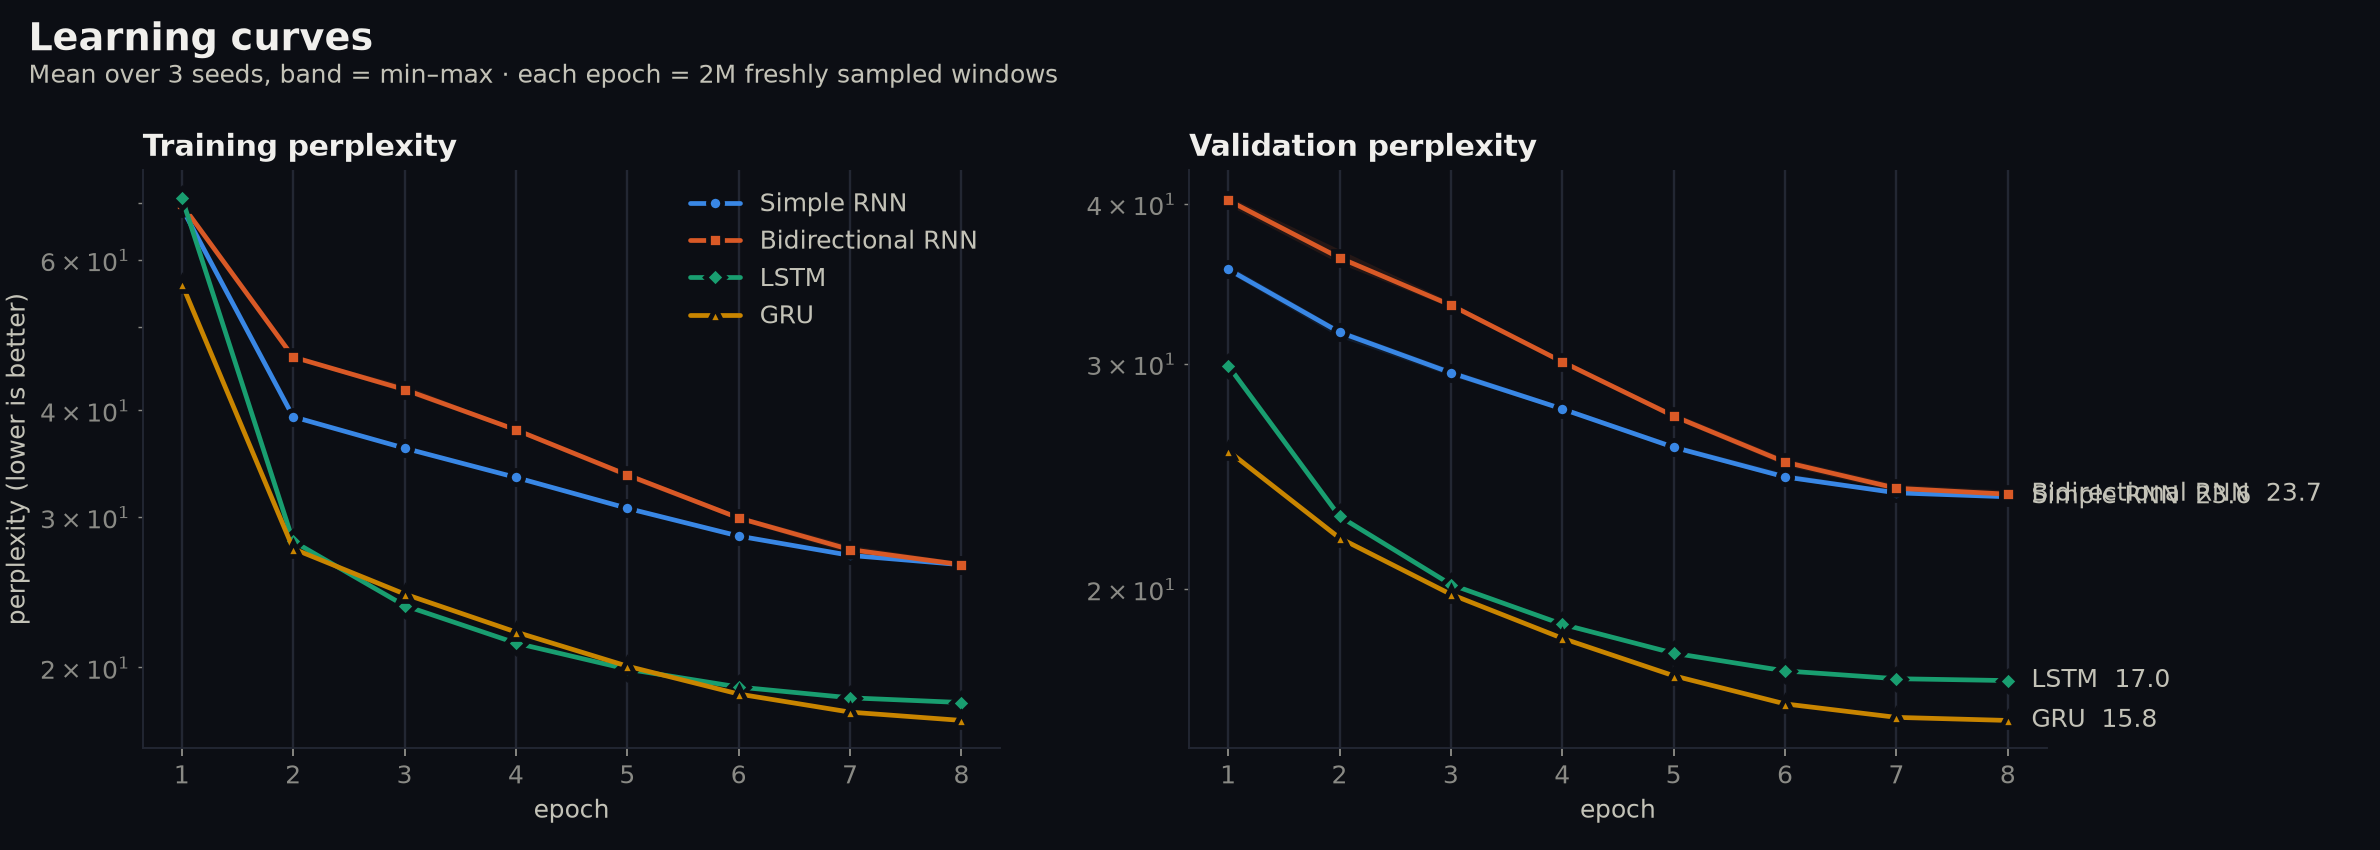

In [9]:
display(Image(P / '02_learning_curves.png'))

## 4 · Quantitative evaluation *(Task ii)*

In [10]:
summary = pd.read_csv(M / "summary_by_model.csv", index_col=0)
cols = ["test_loss", "test_ppl", "test_top1", "test_top5", "time_per_epoch_s", "ms_per_token"]
table = pd.DataFrame({c: summary[f"{c}_mean"].map("{:.3f}".format) + " ± " + summary[f"{c}_std"].map("{:.3f}".format) for c in cols})
table.insert(0, "params", summary["params_total"])
table.index = summary["model"]
table

,params,test_loss,test_ppl,test_top1,test_top5,time_per_epoch_s,ms_per_token
model,,,,,,,
Simple RNN,3310400,3.170 ± 0.005,23.803 ± 0.108,0.366 ± 0.000,0.621 ± 0.001,118.897 ± 4.155,2.798 ± 0.498
Bidirectional RNN,5719872,3.172 ± 0.007,23.867 ± 0.161,0.374 ± 0.001,0.624 ± 0.001,261.575 ± 8.657,5.641 ± 1.285
LSTM,4001600,2.842 ± 0.003,17.149 ± 0.045,0.415 ± 0.001,0.670 ± 0.000,285.758 ± 20.675,0.559 ± 0.037
GRU,3771200,2.771 ± 0.004,15.971 ± 0.058,0.424 ± 0.000,0.683 ± 0.000,254.834 ± 14.297,3.310 ± 0.063


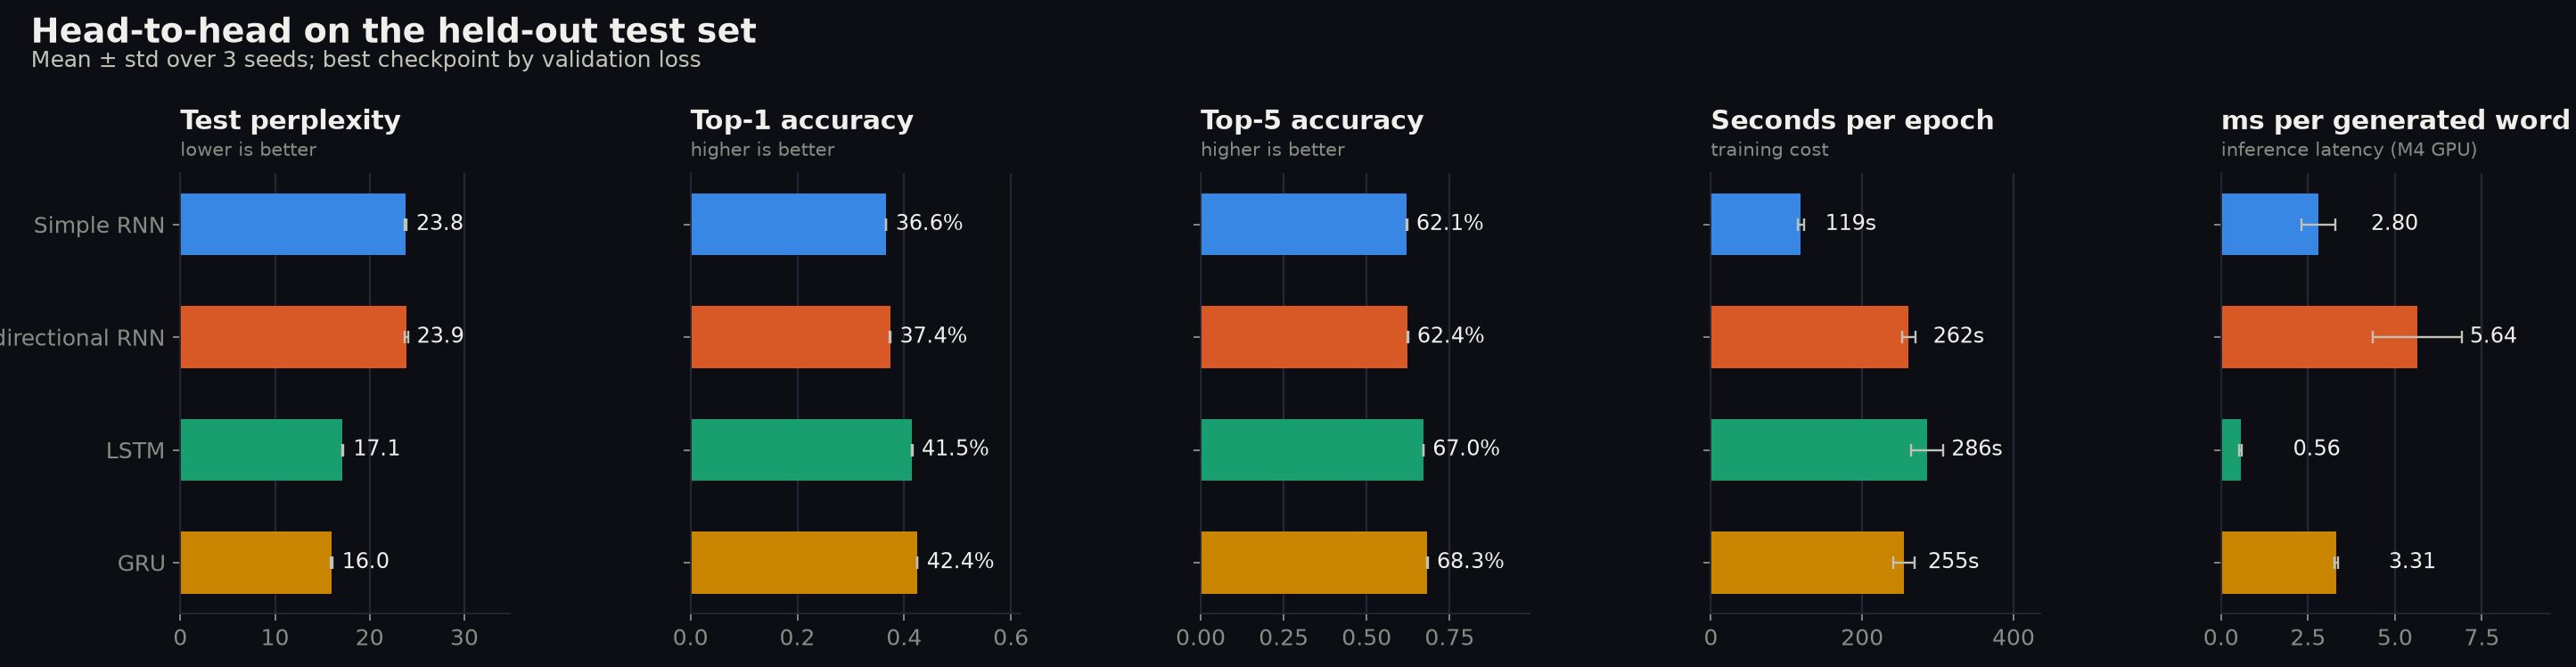

In [11]:
display(Image(P / '03_test_metrics.png'))

In [12]:
speed = M / "speed_benchmark.csv"
if speed.exists():
    display(Markdown("**Controlled speed benchmark** (all models timed back-to-back on an idle machine):"))
    display(pd.read_csv(speed).set_index("model")[["total", "recurrent_core", "train_ms_per_batch", "infer_ms_per_word", "est_min_per_epoch"]])

**Controlled speed benchmark** (all models timed back-to-back on an idle machine):

,total,recurrent_core,train_ms_per_batch,infer_ms_per_word,est_min_per_epoch
model,,,,,
Simple RNN,3310400,230400,20.840,2.383,1.357
Bidirectional RNN,5719872,591872,44.801,4.849,2.917
LSTM,4001600,921600,47.676,0.410,3.104
GRU,3771200,691200,47.521,3.182,3.094
Transformer,3336128,1779456,118.661,0.824,7.725


**Parameter-matched variant** — hidden size re-tuned so every model has ≈ the LSTM's parameter count:

,model,hidden_dim,params_total,test_ppl,test_top1
0,Bidirectional RNN,168,3990144,23.542,0.373
1,GRU,272,3981568,15.861,0.425
2,LSTM,256,4001600,17.189,0.415
3,Simple RNN,324,3981696,23.513,0.374


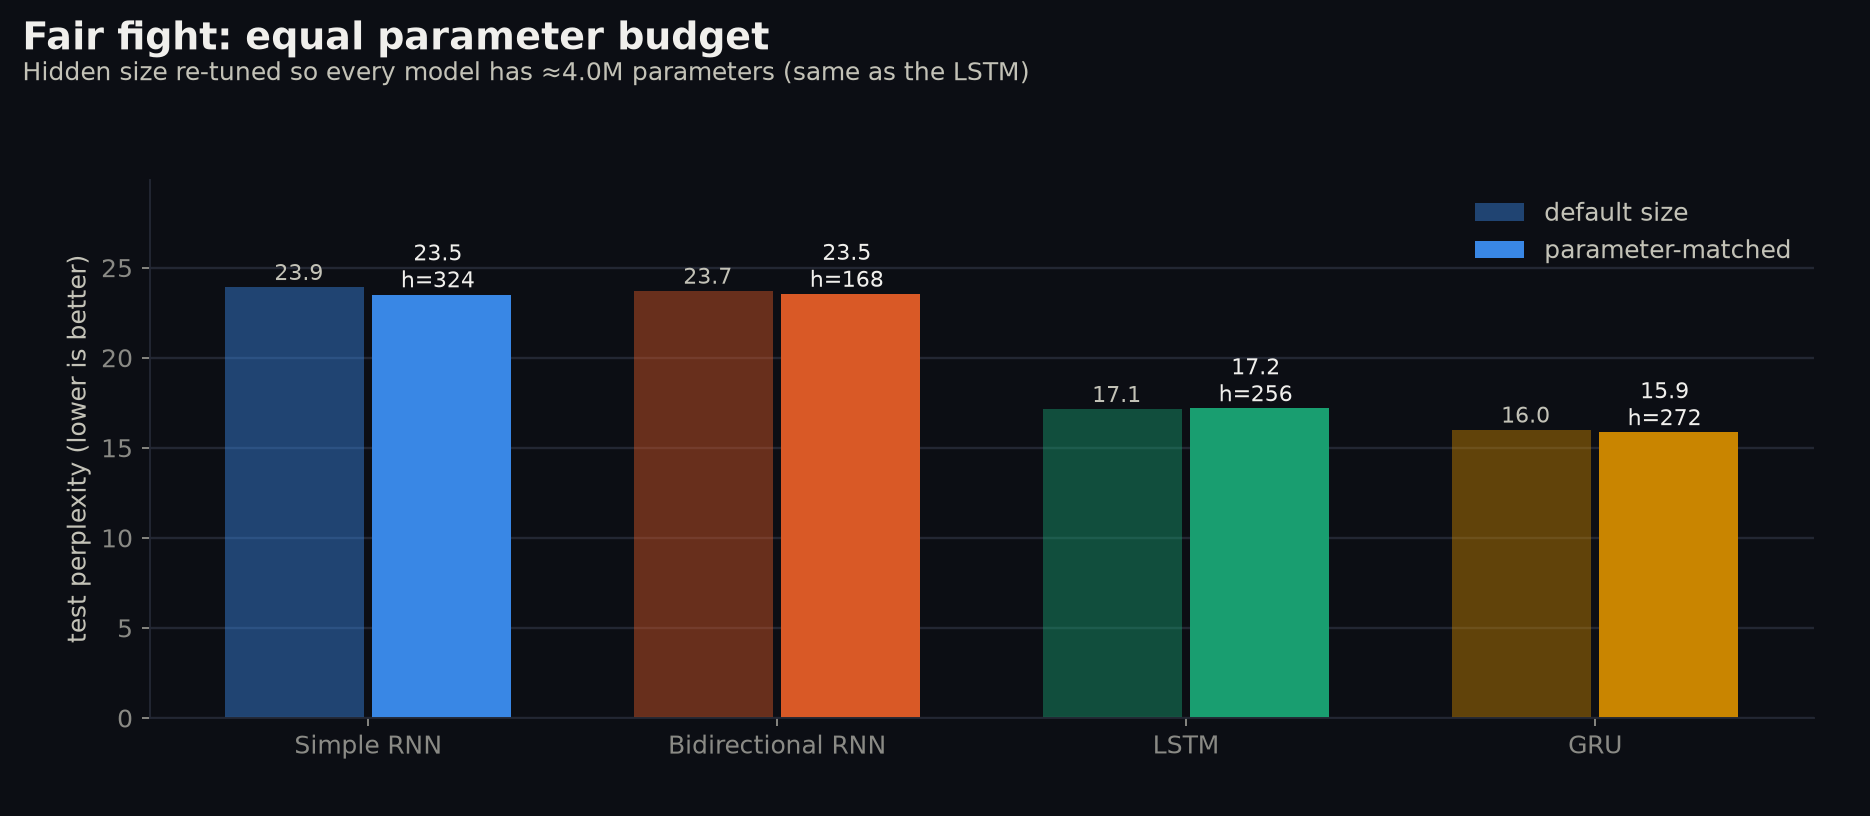

In [13]:
matched = M / "matched.csv"
if matched.exists() and matched.stat().st_size > 10:
    display(Markdown("**Parameter-matched variant** — hidden size re-tuned so every model has ≈ the LSTM's parameter count:"))
    display(pd.read_csv(matched)[["model", "hidden_dim", "params_total", "test_ppl", "test_top1"]])
    display(Image(P / "06_parameter_matched.png"))

### Model comparison and evaluation

- **Gating is what matters.** LSTM and GRU beat both ungated RNNs by about 7 perplexity points (a 28–33 % reduction) and 4–6
  accuracy points. With a 24-word window, the simple RNN's vanishing gradients mean it effectively uses only the last
  few words. You can see this in its text: it changes the pronoun from *she* to *he* mid-story and falls into loops.
- **Bidirectionality doesn't help next-word prediction.** The BiRNN has 73 % more parameters and takes 2× longer to train than the simple RNN,
  yet its perplexity is the same (23.87 vs 23.80). The backward pass can only re-read the past window, because the future is
  unavailable when generating, so it adds capacity but no new information. It does give slightly better consistency
  (0.374 vs 0.302), because summarising the window from both ends helps it hold on to the seed's topic.
- **GRU vs LSTM.** GRU wins on every quantitative metric with 6 % fewer parameters and the same training speed, and
  it stays ahead in the parameter-matched run. Its text is the most fluent of the four recurrent models (GPT-2 perplexity 10.5 vs 13.5)
  and the most diverse (highest distinct-2, lowest self-BLEU). LSTM is marginally better on consistency (0.401 vs 0.397) and
  is the most stable across seeds.
- **Training time.** Simple RNN is cheapest (1.4 min/epoch); LSTM, GRU and BiRNN cost about 2.2× more; the bonus Transformer
  about 5.7×. Results are highly reproducible: perplexity std across seeds is at most 0.16.
- **Weaknesses shared by all four.** Plots drift over a 60-word continuation, and characters' names and genders sometimes change. All
  remain far below human text on diversity (distinct-2 ≈ 0.45 vs 0.72 at T = 0.5).

## 5 · Generation and text quality *(Tasks ii & iii)*

For each model's best checkpoint we generate 60 tokens from **5 seed sequences** at **5 temperatures**
(greedy, 0.5, 0.8, 1.0, 1.3), 5 samples each. Every model draws from **the same random-number stream**, so differences
are due to the model, not luck. Text quality is then scored automatically:

| Quality | Metric |
|---|---|
| Coherence | perplexity of the continuation under **GPT-2** (an independent, much larger model) — lower = more natural |
| Contextual consistency | cosine similarity of **MiniLM** sentence embeddings of seed vs continuation |
| Diversity | distinct-1/2/3 (unique n-grams ÷ all n-grams); self-BLEU between samples of the same prompt |
| Repetition | share of repeated 3-grams within a sample |

In [14]:
proper = set(json.loads((ROOT / "data" / "processed" / "proper_nouns.json").read_text()))
dev = device()
models = {k: load_model(ROOT / "models" / f"{k}.pt", dev) for k in KINDS}
seed_text = cfg["generate"]["seeds_text"][0]
print("SEED:", detokenize(tokenize(seed_text), proper), "\n")
for T in cfg["generate"]["temperatures"]:
    print(f"── temperature {T if T > 0 else '0 (greedy)'} " + "─" * 50)
    for k, m in models.items():
        g = torch.Generator().manual_seed(0)
        out = generate(m, vocab, seed_text, 40, T, cfg["data"]["window"], g)
        print(f"{DISPLAY[k]:>18}: {detokenize(out, proper, continuation=True)}")
    print()

SEED: Once upon a time, there was a little girl named Lily. She 

── temperature 0 (greedy) ──────────────────────────────────────────────────
        Simple RNN: loved to play outside in the park. One day, she saw a big tree. He was so excited to see the bird. He was so happy that he had been able to go home. He


 Bidirectional RNN: loved to play outside in the park. One day, she saw a big, scary dog. She wanted to play with her toys and make a big smile. She said, "Wow, Lily,
              LSTM: loved to play outside in the park. One day, she saw a big tree with a big tree. She wanted to play with it, but she was too fast. She wanted to see what was


               GRU: loved to play outside in the sunshine. One day, she saw a big, scary dog. The dog was very sad and wanted to play with the ball. Lily didn't want to play with the ball

── temperature 0.5 ──────────────────────────────────────────────────
        Simple RNN: loved to play with his toys and read the sun in the park. One day, she went to the park with her mom. She was excited to make a new friend. The end.


 Bidirectional RNN: loved to play with her toys and she was very happy. One day, she saw a big, shiny dress on the ground. She was excited to see what was inside. The little girl was very
              LSTM: loved to play with her toys and read the cherries. One day, she saw a big box in the garden. She was curious and wanted to touch it. She asked her mother to buy her to


               GRU: loved to play with her toys and read the book. One day, her mom said, "It's time to go home, Lily. You have to follow the rules and make sure to be careful.

── temperature 0.8 ──────────────────────────────────────────────────
        Simple RNN: loved to play with his toys and read the ceiling of some colours playing in the park. One day, she would pick up the blocks and make a big mess. When he finished on the crack,


...

               GRU: loved to play with her toys and read the ceiling. One day, her mom said she would send it to her dad. She said yes and gave Tommy a treat. Lily felt very happy and excited

── temperature 1.0 ──────────────────────────────────────────────────
        Simple RNN: loved to play with his toys and read the ceiling of some colours playing in the sea. One day, she would pick up gloomy and faster. One day, she saw that the meat was bad.


 Bidirectional RNN: loved to play with her umbrella and she was happy to touch her playing in the park. One day, she would pick up gloomy and twirl around along with her mom. Lily felt very bored and excited
              LSTM: loved to play with her toys and read the cherries. Everyday, she showed her friends all their toys and was very independent. She was very excited to make things because she was the best next thing to
               GRU: loved to play with her toys and read the ceiling of some colours playing in her room. One day, she would walk for a walk and explore along with her mom. One day, they came to

── temperature 1.3 ──────────────────────────────────────────────────


        Simple RNN: forgave Lily, dad and Leo and Ben was hungry along some colours playing fruits. Every day, Paul has such an x ray gloomy day and excited along with his mom when he the meat next and it


 Bidirectional RNN: loved to play on her umbrella and she was happy to touch it playing her toys. One day, Lily was mean to visit gloomy. Every time along with her teddy bear saw the whole room and greeted
              LSTM: loved to play with her toys and read the cherries along some colours playing her toys. One week, Lily was on a pretty gloomy day and excited along with her mom when she fell on a bad box


               GRU: loved to play with her toys and read the ceiling books everyday. She showed each yoga all around her pile measure would lead people gloomy. Every time along the box below, Lily the whole knob came to



In [15]:
tq = pd.read_csv(M / "text_quality.csv")
tq.pivot_table(index="model", columns="temperature", values=["gpt2_ppl", "distinct_2", "repetition", "consistency", "self_bleu"]).round(3)

consistency                             distinct_2         \
temperature               0.0    0.5    0.8    1.0    1.3        0.0    0.5   
model                                                                         
Bidirectional RNN       0.355  0.374  0.347  0.349  0.317      0.092  0.419   
GRU                     0.441  0.397  0.393  0.390  0.343      0.104  0.478   
LSTM                    0.343  0.401  0.332  0.336  0.344      0.099  0.441   
Simple RNN              0.304  0.302  0.300  0.305  0.278      0.092  0.446   
Transformer             0.538  0.479  0.473  0.428  0.379      0.123  0.458   

                                        ... repetition                       \
temperature          0.8    1.0    1.3  ...        0.0    0.5    0.8    1.0   
model                                   ...                                   
Bidirectional RNN  0.652  0.757  0.890  ...      0.262  0.059  0.004  0.002   
GRU                0.636  0.760  0.891  ...      0.276  0.077  0.017  0.006   
LSTM               0.639  0.777  0.873  ...      0.120  0.066  0.014  0.008   
Simple RNN         0.656  0.776  0.907  ...      0.209  0.055  0.008  0.009   
Transformer        0.613  0.722  0.880  ...      0.200  0.074  0.016  0.010   

                         self_bleu                              
temperature          1.3       0.0    0.5    0.8    1.0    1.3  
model                                                           
Bidirectional RNN  0.000       1.0  0.306  0.158  0.108  0.055  
GRU                0.000       1.0  0.274  0.155  0.099  0.055  
LSTM               0.002       1.0  0.301  0.167  0.091  0.063  
Simple RNN         0.003       1.0  0.296  0.137  0.094  0.045  
Transformer        0.003       1.0  0.356  0.212  0.115  0.061  

[5 rows x 25 columns]

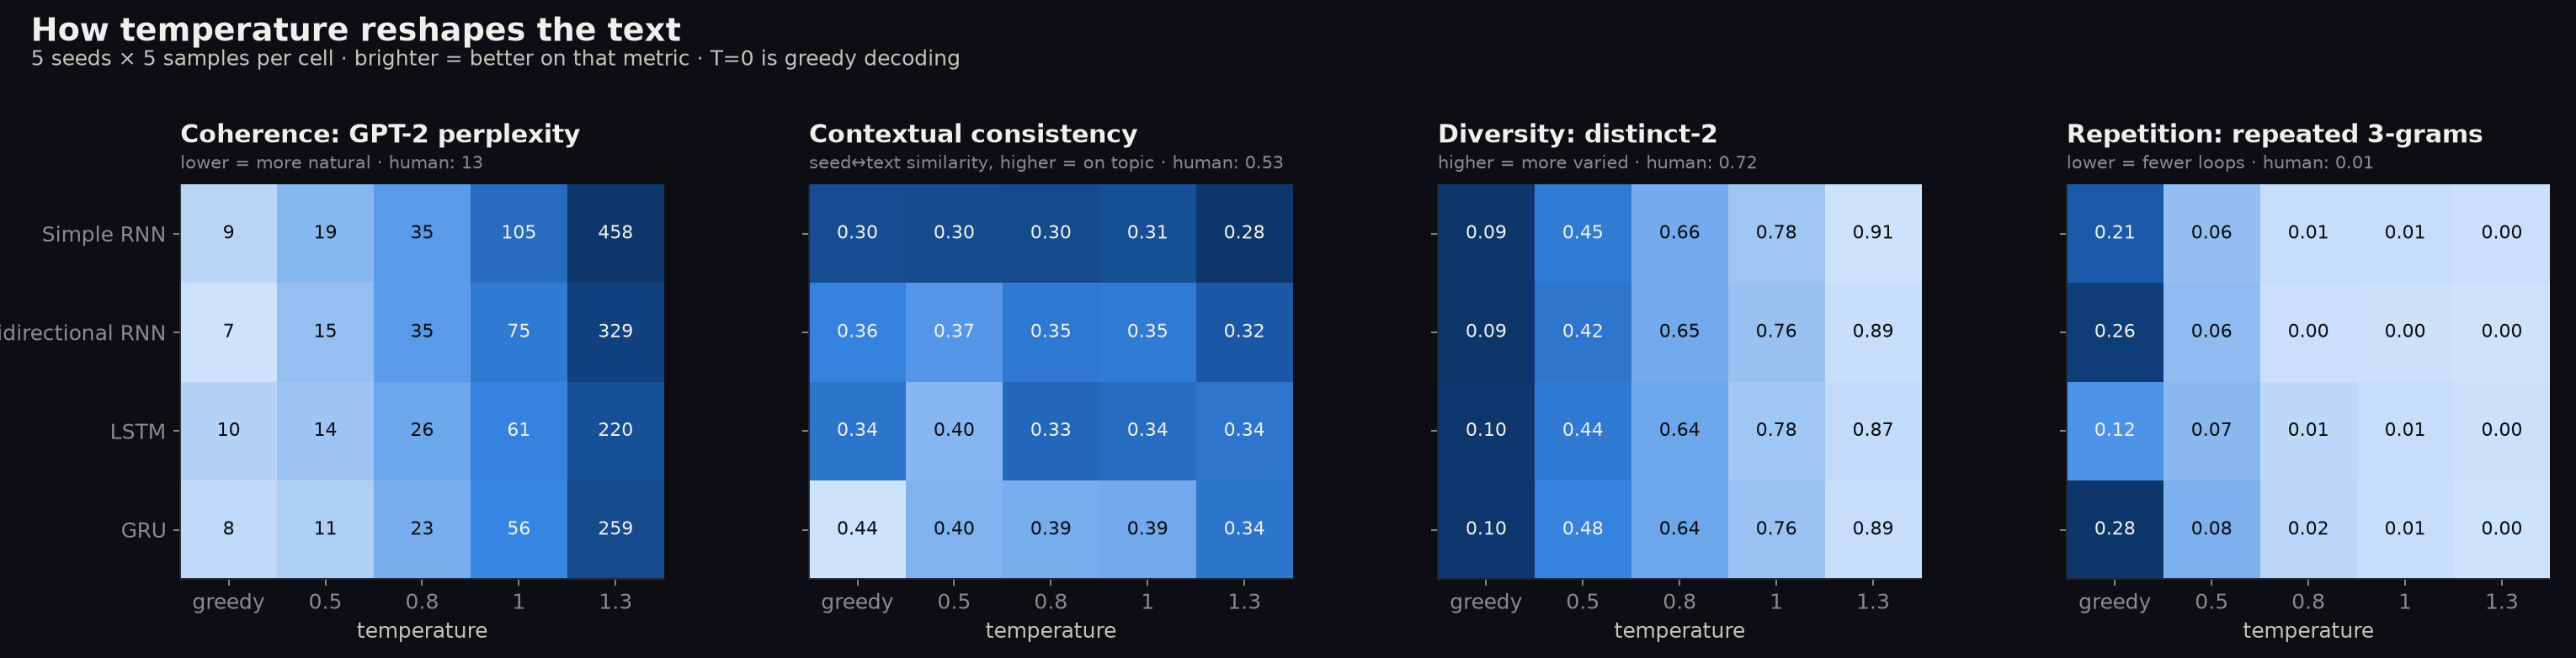

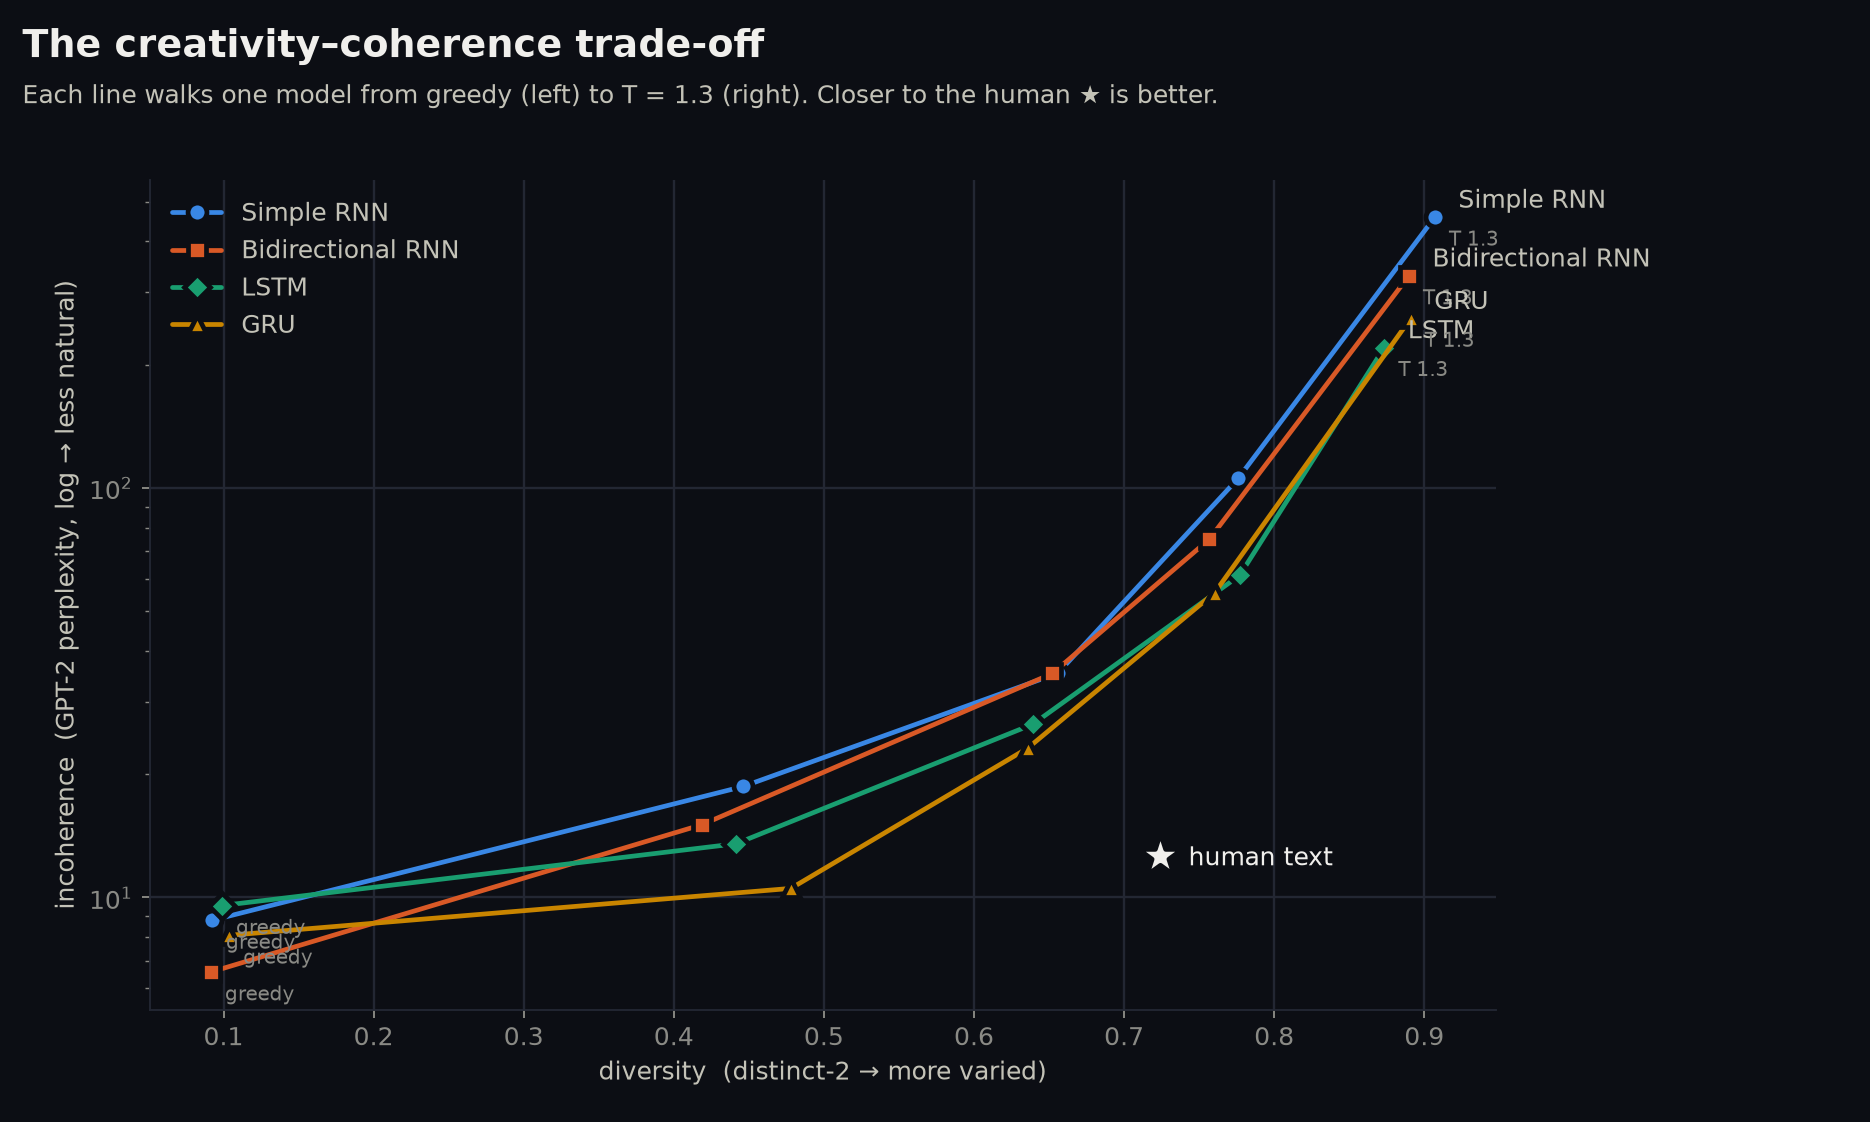

In [16]:
display(Image(P / '04_temperature_heatmaps.png')); display(Image(P / '05_temperature_frontier.png'))

In [17]:
# Human reference row: real TinyStories continuations scored by the same judges.
tq[tq.kind == "human"]

,kind,model,temperature,gpt2_ppl,consistency,distinct_1,distinct_2,distinct_3,self_bleu,repetition,length
25,human,Human (TinyStories),NaN,12.638,0.532,0.28,0.724,0.926,NaN,0.01,60.0


### Qualitative: generated-text quality at T = 0.5 (5 seeds × 5 samples per model)

| Model | Coherence: GPT-2 ppl ↓ | Consistency ↑ | Distinct-2 ↑ | Self-BLEU ↓ | Repetition ↓ |
|---|---:|---:|---:|---:|---:|
| Simple RNN | 18.7 | 0.302 | 0.446 | 0.296 | 0.055 |
| Bidirectional RNN | 15.1 | 0.374 | 0.419 | 0.306 | 0.059 |
| LSTM | 13.5 | **0.401** | 0.441 | 0.301 | 0.066 |
| **GRU** | **10.5** | 0.397 | **0.478** | **0.274** | 0.077 |
| *Transformer (bonus)* | *11.1* | *0.479* | *0.458* | *0.356* | *0.074* |
| *Human TinyStories text* | *12.6* | *0.532* | *0.724* | — | *0.010* |

Every sample is in `results/samples/SAMPLES.md`. An example with the same seed, T = 0 (greedy):

> **Seed:** *Once upon a time, there was a little girl named Lily. She*
>
> **Simple RNN:** loved to play outside in the park. One day, she saw a big tree. He was so excited to see the bird. He was so happy that he had been able to go home. He was so happy that he had been able to go home.
>
> **GRU:** loved to play outside in the sunshine. One day, she saw a big, scary dog. The dog was very sad and wanted to play with the ball. Lily didn't want to play with the ball anymore. She wanted to play with it, but she didn't know how to get it. She tried

### Sampling-temperature analysis

The same 5 seeds were continued for 60 words at **T ∈ {0 (greedy), 0.5, 0.8, 1.0, 1.3}**, using the same random stream for
every model. The table gives values averaged over the four recurrent models.

| Temperature | Coherence (GPT-2 ppl) | Distinct-2 | Self-BLEU | Repetition | What the text looks like |
|---|---:|---:|---:|---:|---|
| 0 (greedy) | 8.3 | 0.10 | 1.00 | **0.22** | fluent but deterministic; falls into loops (*"He was so happy… He was so happy…"*) |
| **0.5** | 14.5 | 0.45 | 0.29 | 0.06 | **best balance**: grammatical, on-topic, varied |
| 0.8 | 30.0 | 0.65 | 0.15 | 0.01 | more creative, occasional odd word choices |
| 1.0 | 74.3 | 0.77 | 0.10 | 0.01 | loses the thread; odd collocations |
| 1.3 | 316.6 | 0.89 | 0.05 | 0.00 | close to word salad |


- **Coherence falls monotonically** as temperature rises (GPT-2 perplexity rises about 40× from T=0 to T=1.3), because flattening the
  softmax gives rare, unsuitable words more probability.
- **Diversity rises monotonically.** Distinct-2 goes from 0.10 to 0.89 and self-BLEU from 1.0 to 0.05.
- **Repetition is a low-temperature problem.** Greedy decoding always takes the most likely word, so once a phrase
  repeats the model gets stuck repeating it (repetition rate up to 0.28 for the GRU and BiRNN). At T ≥ 0.5 repetition
  almost disappears.
- **The best range is T ≈ 0.5–0.8.** At T = 0.5 every model is close to the human reference coherence (12.6) with
  little repetition, and at 0.8 diversity approaches human level (0.65 vs 0.72). Above 1.0 the text falls apart for every
  architecture.
- **Robustness to temperature differs between models.** At T = 1.0 the GRU (55.5) and LSTM (61.1) stay much more coherent than the BiRNN (74.9)
  and Simple RNN (105.4). Gated models produce sharper distributions, so they tolerate more randomness.

## 6 · Conclusion

## Conclusion: best-performing model

**The GRU provides the most effective autoregressive generation for TinyStories.**
- It has the lowest test loss and perplexity (**15.97 ± 0.06**) and the highest top-1/top-5 accuracy (42.4 % / 68.3 %) of the four models,
  and it keeps that lead when every model has the same number of parameters.
- It has the best coherence among recurrent models at T = 0.5 (GPT-2 perplexity 10.5, better than the human-text reference of 12.6), the highest
  diversity, and the most coherent text of any recurrent model at T = 1.0 (GPT-2 perplexity 55.5).
- It needs fewer parameters than the LSTM at the same training cost.

Recommended setting: **GRU at T ≈ 0.5** for coherent stories, or T ≈ 0.8 for more variety. The LSTM is a close second; the
Simple RNN and BiRNN are clearly weaker, and bidirectionality brings no benefit for next-word generation. The bonus
Transformer (perplexity 12.7) shows where the field went next, but it was not part of the four-model comparison.